--- Starting Training ---
Epoch [1/10] - Loss: 0.5382
Epoch [2/10] - Loss: 0.4083
Epoch [3/10] - Loss: 0.3750
Epoch [4/10] - Loss: 0.3541
Epoch [5/10] - Loss: 0.3367
Epoch [6/10] - Loss: 0.3202
Epoch [7/10] - Loss: 0.3133
Epoch [8/10] - Loss: 0.3008
Epoch [9/10] - Loss: 0.2940
Epoch [10/10] - Loss: 0.2861

Test Accuracy: 87.85%
Finished!


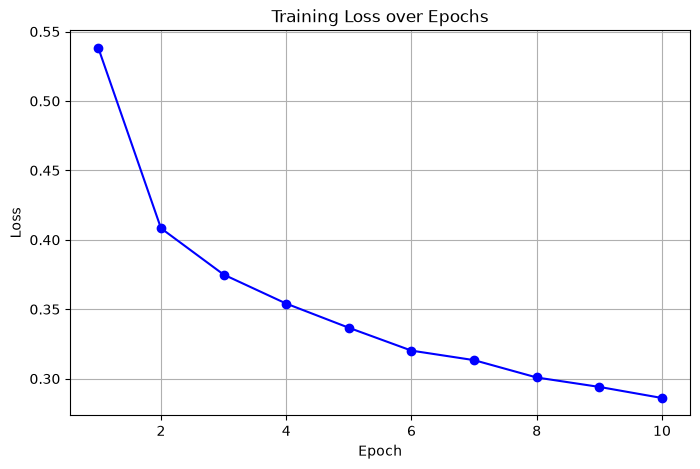

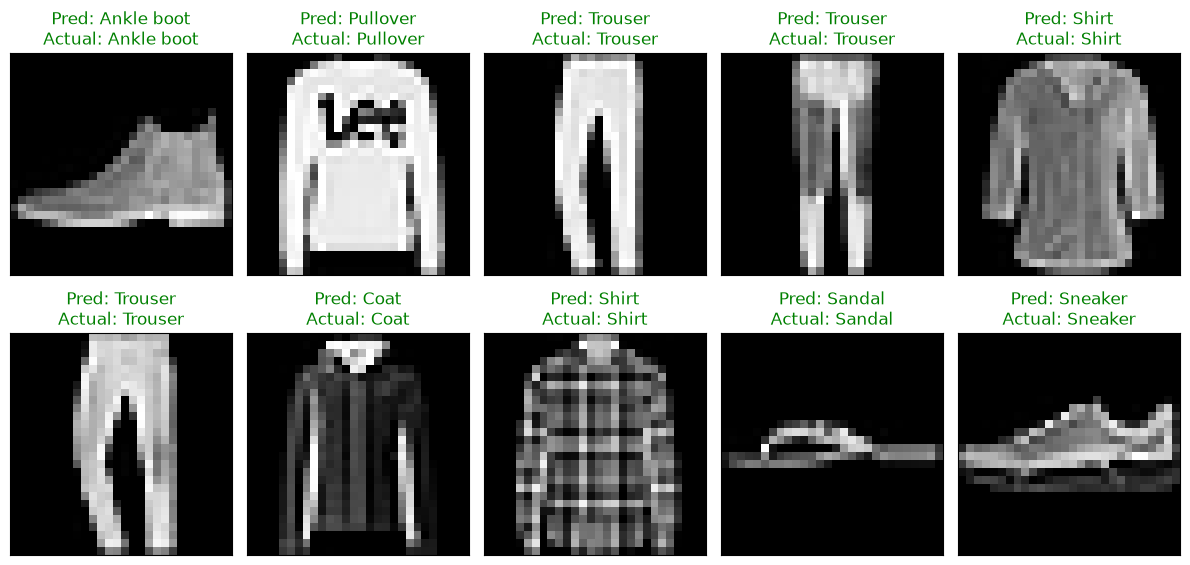

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# 1. Load Dataset & Transforms
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

train_dataset = datasets.FashionMNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.FashionMNIST(root='./data', train=False, download=True, transform=transform)

train_loader = DataLoader(dataset=train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=64, shuffle=False)

classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
           'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# 2. Build Model
class FashionClassifier(nn.Module):
    def __init__(self):
        super(FashionClassifier, self).__init__()
        self.flatten = nn.Flatten()
        self.fc_layers = nn.Sequential(
            nn.Linear(28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 10)
        )
        
    def forward(self, x):
        x = self.flatten(x)
        return self.fc_layers(x)

model = FashionClassifier().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# 3. Training Loop
epochs = 10
train_losses = []

print("--- Starting Training ---")
for epoch in range(epochs):
    running_loss = 0.0
    model.train()
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        
    epoch_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_loss)
    print(f"Epoch [{epoch+1}/{epochs}] - Loss: {epoch_loss:.4f}")

# 4. Evaluation
model.eval()
correct, total = 0, 0
with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"\nTest Accuracy: {100 * correct / total:.2f}%")

# 5. Save Model
torch.save(model.state_dict(), "fashion_mnist_model.pth")

# 6. Visualize Loss
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses, marker='o', color='b', label='Training Loss')
plt.title('Training Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.savefig('loss_graph.png')

# 7. Display Predictions
dataiter = iter(test_loader)
images, labels = next(dataiter)
images, labels = images.to(device), labels.to(device)
outputs = model(images)
_, preds = torch.max(outputs, 1)

plt.figure(figsize=(12, 6))
for idx in range(10):
    ax = plt.subplot(2, 5, idx + 1, xticks=[], yticks=[])
    img = images[idx].cpu().squeeze().numpy() / 2 + 0.5
    plt.imshow(img, cmap='gray')
    ax.set_title(f"Pred: {classes[preds[idx]]}\nActual: {classes[labels[idx]]}",
                 color=("green" if preds[idx]==labels[idx] else "red"))
plt.tight_layout()
plt.savefig('predictions_display.png')
print("Finished!")